In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans

# Definir los nombres exactos de las 3 imágenes seleccionadas (Escenario C: Cultivos)
archivos_imagenes = [
    "Coatepec.png",  # Zona 1: Parcelas cañeras (Referencia)
    "Actopan.png",    # Zona 2: Parcelas con surcos y labranza
    "Perote.png"     # Zona 3: Riego por pivote central y descanso
]

nombres_zonas = ["Zona 1 (Coatepec)", "Zona 2 (Actopan)", "Zona 3 (Perote)"]
print("Librerías importadas y nombres de archivos listos.")

Librerías importadas y nombres de archivos listos.


Zona 1 (Coatepec.png): 1278x716 px (716px alto x 1278px ancho), Canales: 3, Rango: [0, 250]
Zona 2 (Actopan.png): 846x718 px (718px alto x 846px ancho), Canales: 3, Rango: [0, 254]
Zona 3 (Perote.png): 1445x712 px (712px alto x 1445px ancho), Canales: 3, Rango: [0, 246]


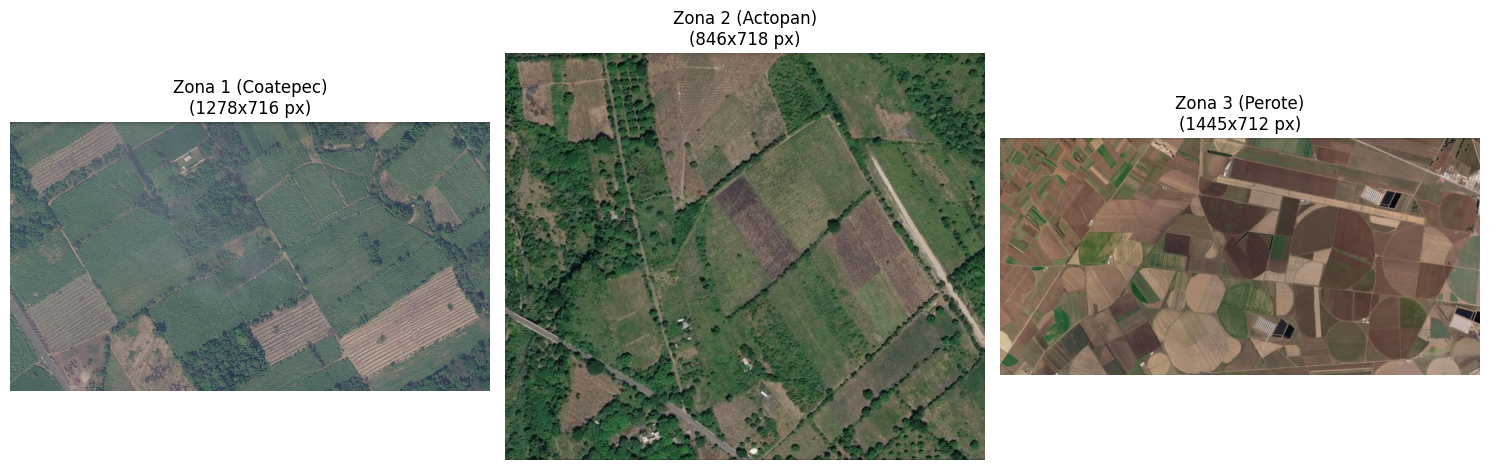

In [8]:
imagenes_rgb = []

plt.figure(figsize=(15, 5))
for i, archivo in enumerate(archivos_imagenes):
    img_bgr = cv2.imread(archivo)
    if img_bgr is None:
        raise FileNotFoundError(f"No se encontró el archivo: {archivo}. Verifica que esté en la misma carpeta.")
    
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    imagenes_rgb.append(img_rgb)
    
    alto, ancho, canales = img_rgb.shape
    rango_min, rango_max = img_rgb.min(), img_rgb.max()
    print(f"Zona {i+1} ({archivo}): {ancho}x{alto} px ({alto}px alto x {ancho}px ancho), Canales: {canales}, Rango: [{rango_min}, {rango_max}]")
    
    plt.subplot(1, 3, i+1)
    plt.imshow(img_rgb)
    plt.title(f"{nombres_zonas[i]}\n({ancho}x{alto} px)")
    plt.axis("off")

plt.tight_layout()
plt.show()

Inercias por K:
  K=2: 1630.13
  K=3: 1068.50
  K=4: 796.36
  K=5: 650.21
  K=6: 547.60
  K=7: 469.58
  K=8: 408.17


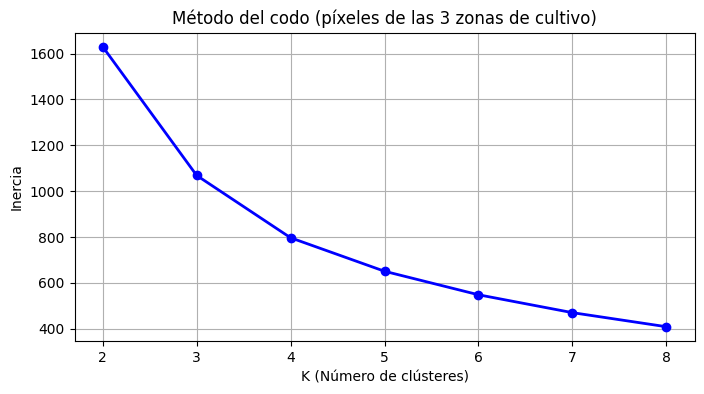

In [9]:
np.random.seed(42)
muestras = []

for img in imagenes_rgb:
    pixeles = img.reshape(-1, 3) / 255.0
    indices = np.random.choice(pixeles.shape[0], size=30000, replace=False)
    muestras.append(pixeles[indices])

muestra_global = np.vstack(muestras)

valores_k = range(2, 9)
inercias = []

for k in valores_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(muestra_global)
    inercias.append(km.inertia_)

print("Inercias por K:")
for k, iner in zip(valores_k, inercias):
    print(f"  K={k}: {iner:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercias, 'bo-', linewidth=2, markersize=6)
plt.title("Método del codo (píxeles de las 3 zonas de cultivo)")
plt.xlabel("K (Número de clústeres)")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

Centroides RGB obtenidos (K=5):
  Clúster 0: RGB (43, 62, 44) | Verdor=37 -> Cobertura vegetal vigorosa / cultivo activo
  Clúster 1: RGB (121, 107, 89) | Verdor=4 -> Suelo húmedo / labranza reciente o sombra densa
  Clúster 2: RGB (157, 140, 125) | Verdor=-2 -> Suelo expuesto seco / rastrojo / sin cobertura
  Clúster 3: RGB (82, 89, 71) | Verdor=25 -> Cobertura vegetal vigorosa / cultivo activo
  Clúster 4: RGB (97, 114, 108) | Verdor=23 -> Suelo expuesto seco / rastrojo / sin cobertura


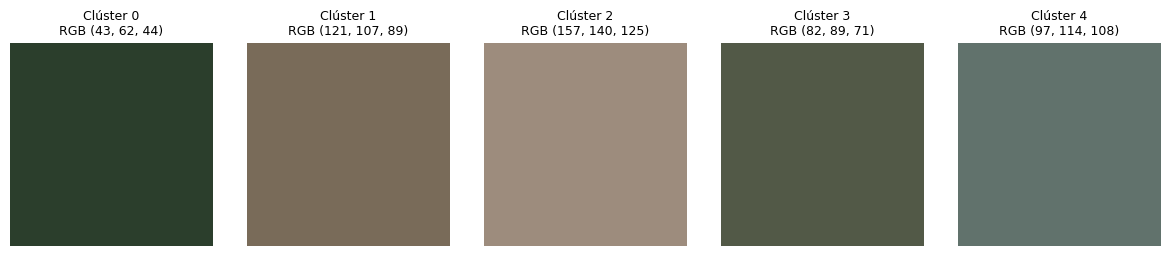

In [10]:
K_OPTIMO = 5
kmeans_comun = KMeans(n_clusters=K_OPTIMO, random_state=42, n_init=10)
kmeans_comun.fit(muestra_global)

centroides_rgb = (kmeans_comun.cluster_centers_ * 255).round().astype(int)

# Calcular índice de verdor (2*G - R - B) y brillo para clasificar automáticamente cada clúster
indice_verdor = 2 * centroides_rgb[:, 1] - centroides_rgb[:, 0] - centroides_rgb[:, 2]
brillo = centroides_rgb.mean(axis=1)

# Ordenamos los clústeres según su verdor (los 2 con mayor verdor son cobertura vegetal activa/vigorosa)
orden_verdor = np.argsort(indice_verdor)[::-1]
clusteres_veg_sana = orden_verdor[:2].tolist()

# De los 3 restantes, el más oscuro/intermedio verdoso es transición/sombra o suelo húmedo, y los de menor verdor suelo seco/arado
resto = orden_verdor[2:].tolist()
# Ordenar el resto por brillo para distinguir suelo oscuro/labranza de suelo seco claro
resto_orden_brillo = sorted(resto, key=lambda c: brillo[c])
cluster_suelo_oscuro = [resto_orden_brillo[0]]
clusteres_suelo_seco = resto_orden_brillo[1:]

print("Centroides RGB obtenidos (K=5):")
for idx, c in enumerate(centroides_rgb):
    c_clean = tuple(c.tolist()) # Conversión a enteros limpios
    etiqueta = ""
    if idx in clusteres_veg_sana:
        etiqueta = "-> Cobertura vegetal vigorosa / cultivo activo"
    elif idx in cluster_suelo_oscuro:
        etiqueta = "-> Suelo húmedo / labranza reciente o sombra densa"
    else:
        etiqueta = "-> Suelo expuesto seco / rastrojo / sin cobertura"
    print(f"  Clúster {idx}: RGB {c_clean} | Verdor={int(indice_verdor[idx])} {etiqueta}")

# Visualizar paleta de colores de los 5 clústeres
fig, axes = plt.subplots(1, K_OPTIMO, figsize=(12, 2.5))
for i in range(K_OPTIMO):
    bloque = np.ones((100, 100, 3), dtype=np.uint8) * centroides_rgb[i]
    axes[i].imshow(bloque)
    
    c_clean = tuple(centroides_rgb[i].tolist()) # Conversión a enteros limpios para el título
    axes[i].set_title(f"Clúster {i}\nRGB {c_clean}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

Zona 1: 102 regiones totales detectadas | 0 regiones relevantes (>= 0.5% del área)
Zona 2: 34 regiones totales detectadas | 1 regiones relevantes (>= 0.5% del área)
Zona 3: 92 regiones totales detectadas | 5 regiones relevantes (>= 0.5% del área)


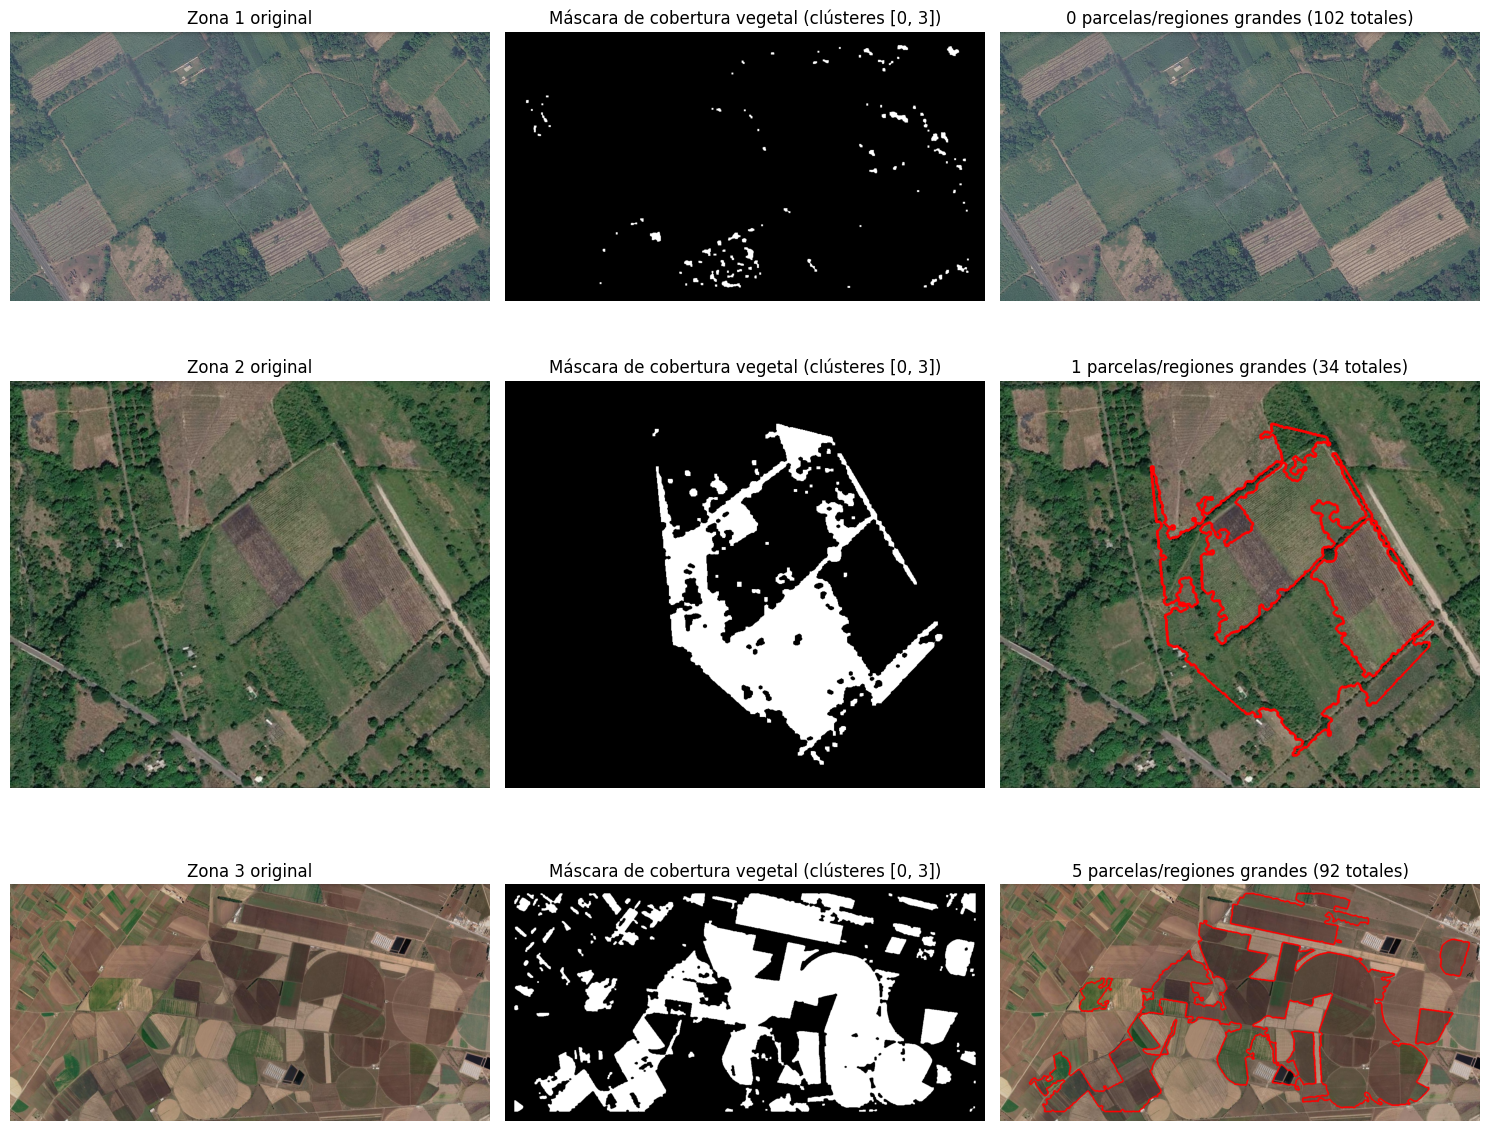

In [11]:
kernel_apertura = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))
kernel_cierre = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

fig, axes = plt.subplots(3, 3, figsize=(15, 13))

for i, img in enumerate(imagenes_rgb):
    h, w, _ = img.shape
    _, mapa_etiquetas = imagenes_segmentadas[i]
    mask_roi = mascaras_roi[i]
    
    # Máscara binaria de vegetación activa dentro de la región de parcelas
    mask_veg = np.isin(mapa_etiquetas, clusteres_veg_sana).astype(np.uint8) * 255
    mask_veg = cv2.bitwise_and(mask_veg, mask_roi)
    
    # Operaciones morfológicas: Apertura (5x5) y Cierre (7x7)
    mask_limpia = cv2.morphologyEx(mask_veg, cv2.MORPH_OPEN, kernel_apertura)
    mask_limpia = cv2.morphologyEx(mask_limpia, cv2.MORPH_CLOSE, kernel_cierre)
    
    # Extracción de contornos externos
    contornos, _ = cv2.findContours(mask_limpia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    area_minima = 0.005 * (h * w) # Al menos 0.5% del área de la imagen
    contornos_grandes = [c for c in contornos if cv2.contourArea(c) >= area_minima]
    
    print(f"Zona {i+1}: {len(contornos)} regiones totales detectadas | {len(contornos_grandes)} regiones relevantes (>= 0.5% del área)")
    
    img_contornos = img.copy()
    cv2.drawContours(img_contornos, contornos_grandes, -1, (255, 0, 0), 3)
    
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Zona {i+1} original")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(mask_limpia, cmap="gray")
    axes[i, 1].set_title(f"Máscara de cobertura vegetal (clústeres {clusteres_veg_sana})")
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(img_contornos)
    axes[i, 2].set_title(f"{len(contornos_grandes)} parcelas/regiones grandes ({len(contornos)} totales)")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [12]:
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

print("Calculando Coeficiente de Silueta (esto puede tardar unos segundos)...")

# Tomamos una submuestra de 10,000 píxeles de nuestra muestra global
np.random.seed(42)
submuestra = muestra_global[np.random.choice(len(muestra_global), size=10000, replace=False)]

siluetas = []

for k in valores_k: # valores_k ya estaba definido de 2 a 8
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(submuestra)
    score = silhouette_score(submuestra, km_k.labels_)
    siluetas.append(score)

df_silueta = pd.DataFrame({"K": list(valores_k), "Silhouette": np.round(siluetas, 3)})
display(df_silueta)

# Identificar el mejor K según Silueta
mejor_k = df_silueta.loc[df_silueta['Silhouette'].idxmax()]
print(f"\nEl valor máximo de Silueta es {mejor_k['Silhouette']} para K = {int(mejor_k['K'])}")

Calculando Coeficiente de Silueta (esto puede tardar unos segundos)...


,K,Silhouette
0,2,0.423
1,3,0.390
2,4,0.357
3,5,0.372
4,6,0.354
5,7,0.345
6,8,0.355



El valor máximo de Silueta es 0.423 para K = 2


In [ ]:
print("Evaluando sensibilidad en el espacio de color LAB...")

# Convertir imágenes RGB a LAB y extraer muestra
muestras_lab = []
lab_imagenes = []

for img in imagenes_rgb:
    # Convertir a LAB y aplanar
    img_lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float64)
    lab_imagenes.append(img_lab)
    
    # Tomar 30,000 pixeles aleatorios
    indices = np.random.choice(len(img_lab), 30000, replace=False)
    muestras_lab.append(img_lab[indices])

muestra_lab_global = np.vstack(muestras_lab)

# Ajustar modelo K-Means con K=5 en LAB
modelo_lab = KMeans(n_clusters=5, n_init=10, random_state=42).fit(muestra_lab_global)
centroides_lab = modelo_lab.cluster_centers_

# El canal a* es el índice 1. Valores menores (negativos) son más verdes.
canal_a = centroides_lab[:, 1]
orden_verdor_lab = np.argsort(canal_a) # De menor a mayor
clusteres_veg_lab = orden_verdor_lab[:2].tolist() # Tomamos los 2 más verdes

print(f"Centroides en LAB. Los 2 clústeres más verdes (menor canal a*) son: {clusteres_veg_lab}")

# Calcular Indicador 1 solo para la Zona 1 (Coatepec, índice 0)
pixeles_coatepec_lab = lab_imagenes[0]
etiquetas_coatepec_lab = modelo_lab.predict(pixeles_coatepec_lab).reshape(imagenes_rgb[0].shape[:2])

# Extraer solo los píxeles dentro de la ROI de Coatepec
etiquetas_roi_lab = etiquetas_coatepec_lab[mascaras_roi[0] > 0]
total_roi_lab = etiquetas_roi_lab.size

pct_veg_coatepec_lab = np.isin(etiquetas_roi_lab, clusteres_veg_lab).sum() / total_roi_lab * 100

print(f"\n---> Indicador 1 de Coatepec en espacio LAB: {pct_veg_coatepec_lab:.2f} %")

Evaluando sensibilidad en el espacio de color LAB...
Centroides en LAB. Los 2 clústeres más verdes (menor canal a*) son: [4, 2]

---> Indicador 1 de Coatepec en espacio LAB: 29.04 %
